In [64]:
import os, glob, pathlib, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pathlib
from collections import  Counter
from ultralytics import YOLO
from tqdm.auto import tqdm
import torch
from tqdm import tqdm
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score

## EDA (Exploratory Data Analysis)


In [65]:
DATA_DIR = "data"   
OUT_DIR  = "data-clean"
os.makedirs(OUT_DIR, exist_ok=True)   # creates the folder if it doesn't exist

TARGET_FPS = 20    
MAX_SIDE   = 960
VIDEO_EXT  = {".mp4", ".avi", ".mov", ".mkv", ".webm"}

In [66]:
def probe(path):
    path = pathlib.Path(path)
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        return dict(file=path.name, path=str(path), ok=False)

    fps = cap.get(cv2.CAP_PROP_FPS)
    n   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    w   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h   = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    ok, _ = cap.read()          
    cap.release()
    
    fps_ok = 1 <= fps <= 240
    return dict(
        file=path.name, stem=path.stem, path=str(path), split=path.parent.name,
        ok=bool(ok), fps=round(fps, 3), frames=n, width=w, height=h,
        duration_s=round(n / fps, 2) if fps_ok else np.nan,
        size_mb=round(path.stat().st_size / 1e6, 2),
        fps_suspicious=not fps_ok,
    )

In [67]:
#analyze the video
video_paths = sorted(p for p in pathlib.Path(DATA_DIR).rglob("*")
                    if p.suffix.lower() in VIDEO_EXT)
meta = pd.DataFrame([probe(p) for p in video_paths])
meta.to_csv(f"{OUT_DIR}/meta.csv", index=False)

print(len(meta), "videos")
print("broken:", (~meta.ok).sum(), "| suspicious fps:", meta.fps_suspicious.sum())
print(meta.split.value_counts())
print(meta.fps.round().value_counts())
meta[["duration_s", "width", "height", "size_mb"]].describe()

416 videos
broken: 0 | suspicious fps: 0
split
subject_1     16
subject_10    16
subject_8     16
subject_7     16
subject_6     16
subject_5     16
subject_4     16
subject_3     16
subject_26    16
subject_25    16
subject_24    16
subject_23    16
subject_22    16
subject_21    16
subject_20    16
subject_2     16
subject_19    16
subject_18    16
subject_17    16
subject_16    16
subject_15    16
subject_14    16
subject_13    16
subject_12    16
subject_11    16
subject_9     16
Name: count, dtype: int64
fps
30.0    416
Name: count, dtype: int64


,duration_s,width,height,size_mb
count,416.000000,416.0,416.0,416.000000
mean,16.029159,1280.0,720.0,9.474760
std,0.723148,0.0,0.0,0.960935
min,13.570000,1280.0,720.0,6.540000
25%,15.580000,1280.0,720.0,9.047500
50%,15.900000,1280.0,720.0,9.650000
75%,16.380000,1280.0,720.0,10.100000
max,18.620000,1280.0,720.0,11.460000


In [68]:
def parse_path(p):
    parts = pathlib.Path(p).parts
    split   = "train" if "train" in parts else "test"
    label   = 1 if "cheat" in parts else (0 if "normal" in parts else np.nan)
    subject = next((x for x in parts if x.startswith("subject_")), None)
    return dict(split=split, label=label, subject=subject)

video_paths = sorted(
    p for split in ["train", "test"]
    for p in pathlib.Path(DATA_DIR, split).rglob("*")
    if p.suffix.lower() in VIDEO_EXT
)
meta = pd.DataFrame([{**probe(p), **parse_path(p)} for p in video_paths])
meta.to_csv(f"{OUT_DIR}/train.csv", index=False)

tr = meta[meta.split == "train"]
print(tr.label.value_counts())                                 
print(tr.groupby("label").subject.nunique())                   
print(tr.groupby(["label", "subject"]).size().unstack(0).head(10))  

label
1    208
0    208
Name: count, dtype: int64
label
0    26
1    26
Name: subject, dtype: int64
label       0  1
subject         
subject_1   8  8
subject_10  8  8
subject_11  8  8
subject_12  8  8
subject_13  8  8
subject_14  8  8
subject_15  8  8
subject_16  8  8
subject_17  8  8
subject_18  8  8


In [69]:
import re
def natural_key(p):                       # frame_2 before frame_10
    return [int(s) if s.isdigit() else s for s in re.split(r"(\d+)", p.name)]

seq_dirs = sorted(d for d in pathlib.Path(DATA_DIR, "test").rglob("*")
                  if d.is_dir() and any(f.is_file() for f in d.iterdir()))
print(len(seq_dirs))                      # should be 1515

d0 = seq_dirs[0]
imgs = sorted([f for f in d0.iterdir() if f.is_file()], key=natural_key)
print(d0.name, len(imgs), [f.name for f in imgs[:5]], "...", imgs[-1].name)
print(cv2.imread(str(imgs[0])).shape, imgs[0].suffix)

sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
print(sub.head())                          # does the id match the folder name?

1515
test_seq_00001 30 ['01.jpg', '02.jpg', '03.jpg', '04.jpg', '05.jpg'] ... 30.jpg
(360, 640, 3) .jpg
               id  label
0  test_seq_00001      0
1  test_seq_00002      0
2  test_seq_00003      0
3  test_seq_00004      0
4  test_seq_00005      0


In [70]:
def frame_diff(frames):
    g = [cv2.cvtColor(cv2.resize(f, (320, 180)), cv2.COLOR_BGR2GRAY).astype(np.float32) for f in frames]
    return np.mean([np.abs(a - b).mean() for a, b in zip(g, g[1:])])

test_d = []
for d in seq_dirs[:40]:
    fs = sorted([f for f in d.iterdir() if f.is_file()], key=natural_key)
    test_d.append(frame_diff([cv2.imread(str(f)) for f in fs]))
print("test:", np.median(test_d))

def read_all(path, max_frames=450):
    cap, out = cv2.VideoCapture(path), []
    while len(out) < max_frames:
        ok, f = cap.read()
        if not ok: break
        out.append(f)
    cap.release(); return out

sample = [read_all(p) for p in tr.sample(10, random_state=0).path]
for k in [1, 2, 3, 5, 10, 15]:
    print(f"stride {k:2d}:", np.median([frame_diff(fr[::k][:30]) for fr in sample]))

test: 0.60103333
stride  1: 0.72028744
stride  2: 0.9405543
stride  3: 1.0085105
stride  5: 1.1010495
stride 10: 1.5557134
stride 15: 2.0109363


### Chain Check

In [71]:
def natural_key(p):
    return [int(s) if s.isdigit() else s for s in re.split(r"(\d+)", p.name)]

test_root = pathlib.Path(DATA_DIR, "test")
seq_dirs = sorted([d for d in test_root.iterdir() if d.is_dir()], key=natural_key)
print(len(seq_dirs), "folders")          # expect 1515

def thumb(p):
    """Small grayscale thumbnail as a flat vector; cheap to compare."""
    g = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
    return cv2.resize(g, (64, 36)).astype(np.float32).ravel()

firsts, lasts, names = [], [], []
for d in seq_dirs:
    fs = sorted([f for f in d.iterdir() if f.is_file()], key=natural_key)
    firsts.append(thumb(fs[0]))
    lasts.append(thumb(fs[-1]))
    names.append(d.name)

F = np.stack(firsts)      
L = np.stack(lasts)     

1515 folders


percentiles of successor distance:
[       0.22        0.34        0.56        0.67        1.78]


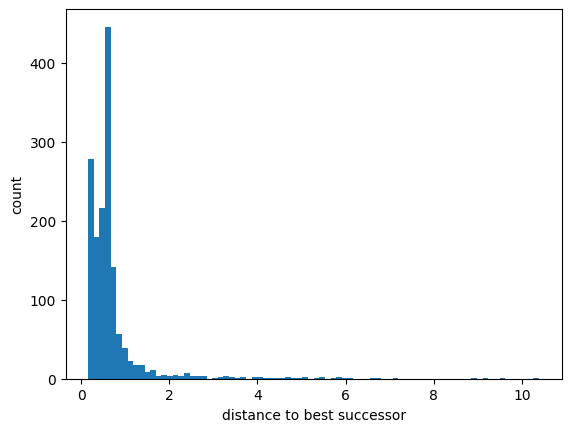

In [72]:
# D[i, j] = how different clip i's last frame is from clip j's first frame
# (loop in blocks to keep memory small)
N = len(names)
D = np.empty((N, N), np.float32)
for i in range(0, N, 256):
    D[i:i+256] = np.abs(L[i:i+256, None, :] - F[None, :, :]).mean(-1)
np.fill_diagonal(D, np.inf)      # a clip can't continue itself

nn_dist = D.min(1)               # distance to the best candidate successor
nn_idx  = D.argmin(1)            # who that candidate is

print("percentiles of successor distance:")
print(np.percentile(nn_dist, [5, 25, 50, 75, 95]).round(2))

plt.hist(nn_dist, bins=80)
plt.xlabel("distance to best successor"); plt.ylabel("count"); plt.show()

In [73]:
THR = 2.0   # set this from the histogram valley; start conservative

pred_idx = D.argmin(0)   # for each clip j, which clip's ending matches j's start best

succ = {}
for i in range(N):
    j = nn_idx[i]
    # accept the link only if it's below threshold AND mutual (j's best predecessor is i)
    if nn_dist[i] < THR and pred_idx[j] == i:
        succ[i] = j

print(f"accepted links: {len(succ)} / {N}")

accepted links: 1413 / 1515


In [74]:
has_pred = set(succ.values())
group_id = np.full(N, -1)
g = 0
for start in range(N):
    if start in has_pred or group_id[start] != -1:
        continue                     # not a chain head
    cur = start
    while True:
        group_id[cur] = g
        if cur not in succ:
            break
        cur = succ[cur]
    g += 1

groups = pd.DataFrame({"seq": names, "group": group_id})
sizes = groups.group.value_counts()
print(f"{g} groups from {N} clips")
print("group size distribution:\n", sizes.value_counts().sort_index())
groups.to_csv(f"{OUT_DIR}/test_groups.csv", index=False)

102 groups from 1515 clips
group size distribution:
 count
1      1
2      1
5      2
6      2
8      1
9      1
10     1
12     1
14     2
15    36
16    38
17    14
18     1
19     1
Name: count, dtype: int64


Chain order: position of each clip inside its chain, used to rebuild test videos.

In [75]:
pos = np.zeros(N, int)
for start in range(N):
    if start in has_pred:
        continue                                   # bukan kepala chain
    cur, k = start, 0
    while True:
        pos[cur] = k; k += 1
        if cur not in succ:
            break
        cur = succ[cur]
groups["pos"] = pos
groups.to_csv(f"{OUT_DIR}/test_groups.csv", index=False)   # now with chain order


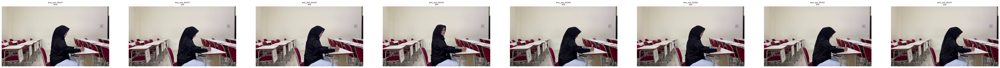

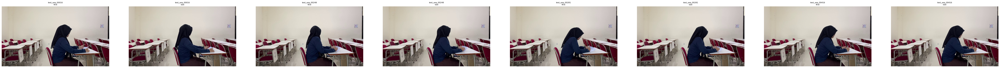

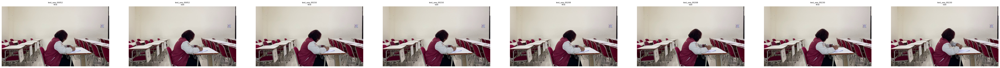

In [76]:
def show_chain(gid, n_clips=4):
    members = [i for i in range(N) if group_id[i] == gid]
    fig, axes = plt.subplots(1, n_clips * 2, figsize=(5 * n_clips * 3, 4))
    k = 0
    for i in members[:n_clips]:
        fs = sorted([f for f in seq_dirs[i].iterdir() if f.is_file()], key=natural_key)
        for f in (fs[0], fs[-1]):                      # first and last frame of each clip
            axes[k].imshow(cv2.imread(str(f))[:, :, ::-1])
            axes[k].set_title(f"{names[i]}\n{'first' if f==fs[0] else 'last'}", fontsize=8)
            axes[k].axis("off"); k += 1
    plt.tight_layout(); plt.show()

big = sizes[sizes > 1].index[:3]
for gid in big:
    show_chain(gid)

In [77]:
print(g, "groups")                                   # expect roughly 100–160
print(sizes.value_counts().sort_index())             # most groups ~10–15 clips?
print("singletons:", (sizes == 1).sum())             # clips that joined nothing

102 groups
count
1      1
2      1
5      2
6      2
8      1
9      1
10     1
12     1
14     2
15    36
16    38
17    14
18     1
19     1
Name: count, dtype: int64
singletons: 1


In [78]:
# Pick the best available device: NVIDIA GPU -> Apple GPU (mps) -> CPU
if torch.cuda.is_available():
    DEVICE = 0
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print("device:", DEVICE)

MODEL_PATH = "yolo11n-pose.pt"                         # file sits next to main.ipynb
assert pathlib.Path(MODEL_PATH).exists(), f"{MODEL_PATH} not found next to the notebook"
MODEL_NAME = pathlib.Path(MODEL_PATH).stem              # "yolo11n-pose"
model = YOLO(MODEL_PATH)

def load_frames(src, stride=3, size=(640, 360)):
    """Read frames from EITHER a video file (train) OR a folder of jpgs (test).
    Every frame is resized to 640x360 so train (1280x720) matches test (640x360)."""
    src = pathlib.Path(src)
    if src.is_dir():                                   # test: folder of 01.jpg ... 30.jpg
        files = sorted([f for f in src.iterdir() if f.is_file()], key=natural_key)[::stride]
        frames = [cv2.imread(str(f)) for f in files]
    else:                                              # train: video file
        cap, frames, idx = cv2.VideoCapture(str(src)), [], 0
        while True:
            ok, f = cap.read()
            if not ok:
                break
            if idx % stride == 0:
                frames.append(f)
            idx += 1
        cap.release()
    return [cv2.resize(f, size) for f in frames if f is not None]

def extract_pose(src, stride=3, batch=32, conf_min=0.3):
    """Return (T, 17, 3): x, y normalized 0-1, keypoint confidence. No person -> NaN."""
    frames = load_frames(src, stride)
    out = []
    for s in range(0, len(frames), batch):
        results = model(frames[s:s+batch], verbose=False, device=DEVICE)
        for r in results:
            kp = np.full((17, 3), np.nan, np.float32)
            if r.keypoints is not None and len(r.boxes) > 0:
                areas = (r.boxes.xywh[:, 2] * r.boxes.xywh[:, 3]).cpu().numpy()
                p = areas.argmax()                     # main person = largest box
                kp[:, :2] = r.keypoints.xyn[p].cpu().numpy()
                kp[:, 2]  = r.keypoints.conf[p].cpu().numpy()
                kp[kp[:, 2] < conf_min, :2] = np.nan   # drop unreliable points
            out.append(kp)
    return np.stack(out) if out else np.empty((0, 17, 3), np.float32)

# quick test on one train video and one test folder before the long run
train_df = meta[meta.split == "train"].reset_index(drop=True)
print("train video:", extract_pose(train_df.path[0]).shape)   # ~ (160, 17, 3)
print("test folder:", extract_pose(seq_dirs[0]).shape)        # (10, 17, 3)


device: mps
train video: (136, 17, 3)
test folder: (10, 17, 3)


In [79]:
# Pose cache: if the keypoints for this model were already extracted, load them instead of re-running YOLO.
# The model name is part of the file name, so switching to e.g. yolo11s-pose.pt re-extracts automatically.
FORCE = False                                             # True = re-extract even if the cache exists

TRAIN_NPZ = pathlib.Path(OUT_DIR, f"poses_train_{MODEL_NAME}.npz")
TEST_NPZ  = pathlib.Path(OUT_DIR, f"poses_test_{MODEL_NAME}.npz")
LEGACY    = {TRAIN_NPZ: pathlib.Path(OUT_DIR, "poses_train.npz"),   # files from the first run (yolo11n)
             TEST_NPZ:  pathlib.Path(OUT_DIR, "poses_test.npz")}

def load_npz(path):
    with np.load(path) as z:
        return {k: z[k] for k in z.files}                 # plain dict, file closed

def cached_poses(npz, expected_keys, sources, desc):
    """Load poses from cache if present and complete; otherwise run extract_pose and save."""
    if not FORCE:
        for p in (npz, LEGACY[npz] if MODEL_NAME == "yolo11n-pose" else None):
            if p is not None and p.exists():
                poses = load_npz(p)
                if set(poses) == set(expected_keys):
                    print(f"{desc}: loaded {len(poses)} from {p.name} (skip extraction)")
                    if p != npz:
                        p.rename(npz)                     # move legacy file to the new name
                    return poses
                print(f"{desc}: {p.name} does not match current data, re-extracting")
    poses = {k: extract_pose(s) for k, s in tqdm(zip(expected_keys, sources),
                                                 total=len(expected_keys), desc=desc)}
    np.savez_compressed(npz, **poses)
    return poses

# keys are always rebuilt because later cells use them
# train_df order comes from sorted(video_paths) in cell 5, so keys map to the same videos every run
train_df["key"] = [f"train_{i:04d}" for i in range(len(train_df))]
train_df.to_csv(f"{OUT_DIR}/train_index.csv", index=False)   # key -> path, label, subject

# TRAIN: 416 videos | TEST: 1515 folders of jpg frames (names[i] = folder name = submission id)
train_poses = cached_poses(TRAIN_NPZ, list(train_df.key), list(train_df.path), "train")
test_poses  = cached_poses(TEST_NPZ,  names,              seq_dirs,            "test")


train: loaded 416 from poses_train_yolo11n-pose.npz (skip extraction)
test: loaded 1515 from poses_test_yolo11n-pose.npz (skip extraction)


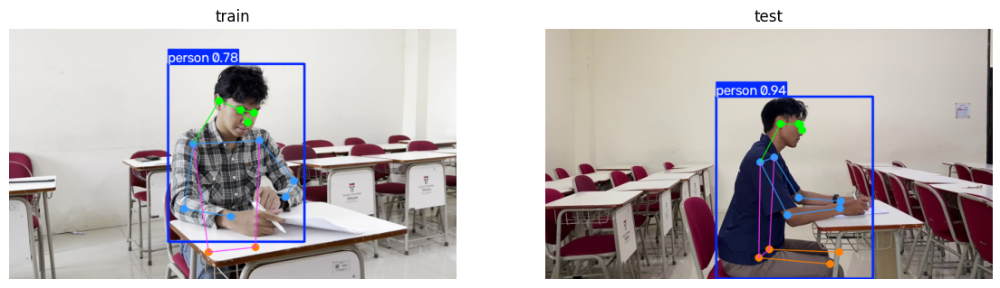

train [       0.01        0.42           0        0.83           0           0           0           0           0           0           0           0           0        0.55        0.49        0.94        0.89]
test [       0.03        0.46        0.01         0.8           0           0           0           0           0           0           0           0           0        0.58        0.41           1        0.99]


In [80]:
# visual check: skeleton on one train frame and one test frame
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, src, title in [(axes[0], train_df.path[0], "train"), (axes[1], seq_dirs[0], "test")]:
    frame = load_frames(src, stride=1)[0]
    r = model(frame, verbose=False, device=DEVICE)[0]
    ax.imshow(r.plot()[:, :, ::-1]); ax.set_title(title); ax.axis("off")
plt.show()

# share of frames where each keypoint is missing (index 0-16)
for split, poses in [("train", train_poses), ("test", test_poses)]:
    allk = np.concatenate([v for v in poses.values() if len(v)])
    print(split, np.isnan(allk[:, :, 0]).mean(0).round(2))


In [81]:
train_df["view"]   = train_df.stem.str.split("_").str[0]          # front / side
train_df["action"] = train_df.stem.str.split("_", n=1).str[1]     # 8 aksi (target saja, bukan fitur)
print(train_df.groupby(["label", "action"]).size())

label  action                
0      Checking_Smartwatch       52
       Looking_Around            52
       Thinking                  52
       Writing_Answers           52
1      Looking_Under_the_Desk    52
       Reading_Hidden_Notes      52
       Repeated_Peeking          52
       Using_Smartwatch          52
dtype: int64


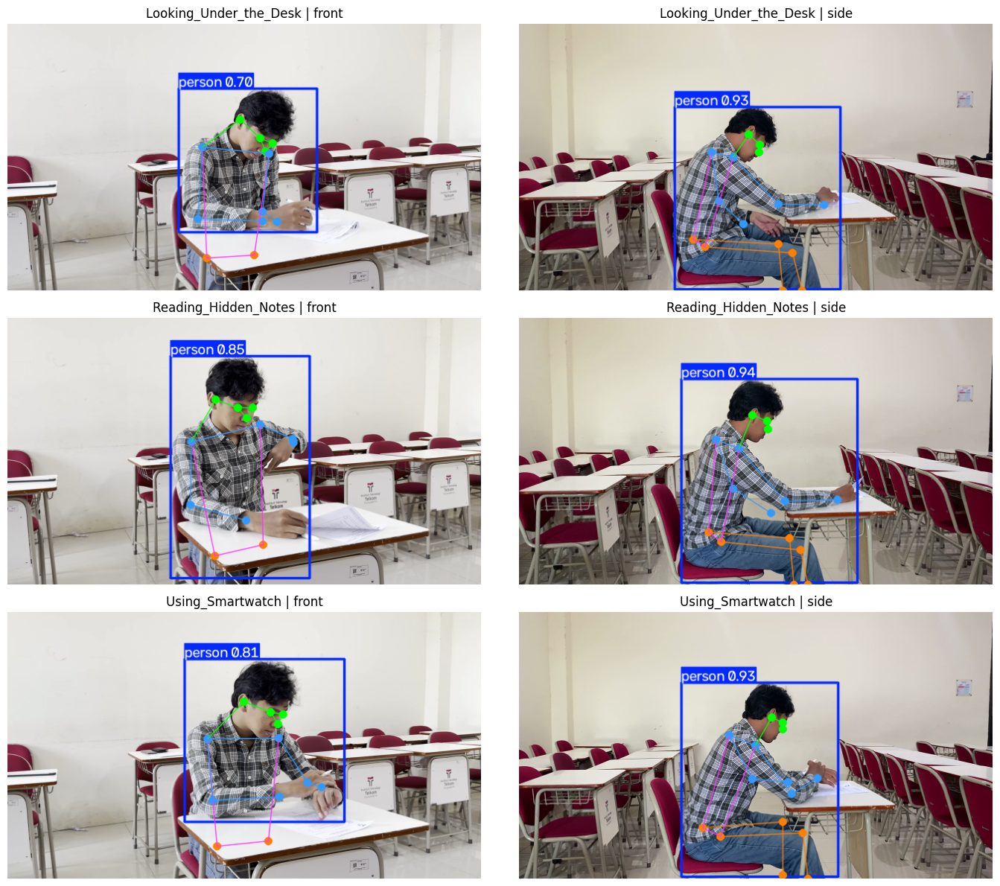

view                    front   side
action                              
Checking_Smartwatch       0.0  0.007
Looking_Around            0.0  0.019
Looking_Under_the_Desk    0.0  0.000
Reading_Hidden_Notes      0.0  0.007
Repeated_Peeking          0.0  0.044
Thinking                  0.0  0.005
Using_Smartwatch          0.0  0.020
Writing_Answers           0.0  0.000


In [82]:
hard = ["Looking_Under_the_Desk", "Reading_Hidden_Notes", "Using_Smartwatch"]
fig, axes = plt.subplots(len(hard), 2, figsize=(14, 4 * len(hard)))
for i, a in enumerate(hard):
    for j, v in enumerate(["front", "side"]):
        r = train_df[(train_df.action == a) & (train_df.view == v)].iloc[0]
        fr = load_frames(r.path, stride=1)
        res = model(fr[len(fr) // 2], verbose=False, device=DEVICE)[0]
        axes[i, j].imshow(res.plot()[:, :, ::-1])
        axes[i, j].set_title(f"{a} | {v}"); axes[i, j].axis("off")
plt.tight_layout(); plt.show()

# persentase frame tanpa orang, per aksi x view
train_df["miss"] = [np.isnan(train_poses[k][:, 0, 0]).mean() for k in train_df.key]
print(train_df.pivot_table(index="action", columns="view", values="miss").round(3))

In [83]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

NOSE, LEYE, REYE, LEAR, REAR, LSH, RSH, LEL, REL, LWR, RWR = range(11)
ASPECT, MAX_GAP = 640 / 360, 2
SWAP_FROM = [LEYE, REYE, LEAR, REAR, LSH, RSH, LEL, REL, LWR, RWR]
SWAP_TO   = [REYE, LEYE, REAR, LEAR, RSH, LSH, REL, LEL, RWR, LWR]

def clean(kp):
    kp = kp[:, :11].astype(np.float32).copy()          # buang pinggul-kaki (tebakan)
    kp[..., 0] *= ASPECT                               # 1 unit x = 1 unit y
    for j in range(11):
        for c in range(2):
            kp[:, j, c] = pd.Series(kp[:, j, c]).interpolate(
                limit=MAX_GAP, limit_direction="both").to_numpy()
    return kp

def mid(a, b):
    return np.nanmean(np.stack([a, b]), axis=0)

def frame_feats(k):
    k = k.copy()
    sh = mid(k[:, LSH, :2], k[:, RSH, :2])
    if np.nanmedian(k[:, NOSE, 0] - sh[:, 0]) < 0:      # menghadap kiri -> cerminkan
        k[..., 0] *= -1
        k[:, SWAP_FROM] = k[:, SWAP_TO]
        sh = mid(k[:, LSH, :2], k[:, RSH, :2])
    s = np.nanmedian(np.linalg.norm(k[:, NOSE, :2] - sh, axis=1))   # skala = jarak hidung-bahu
    if not np.isfinite(s) or s < 1e-6:
        s = np.nan
    rel = lambda j: (k[:, j, :2] - sh) / s
    nose, lw, rw = rel(NOSE), rel(LWR), rel(RWR)
    return pd.DataFrame(dict(
        head_x=nose[:, 0], head_y=nose[:, 1],
        sh_width=np.linalg.norm(k[:, LSH, :2] - k[:, RSH, :2], axis=1) / s,
        sh_tilt=(k[:, LSH, 1] - k[:, RSH, 1]) / s,
        lw_x=lw[:, 0], lw_y=lw[:, 1], rw_x=rw[:, 0], rw_y=rw[:, 1],
        lw_nose=np.linalg.norm(lw - nose, axis=1), rw_nose=np.linalg.norm(rw - nose, axis=1),
        wrist_gap=np.linalg.norm(lw - rw, axis=1),
        lw_conf=k[:, LWR, 2], rw_conf=k[:, RWR, 2],
        leye_conf=k[:, LEYE, 2], lear_conf=k[:, LEAR, 2], rear_conf=k[:, REAR, 2],
    ))

def clip_feats(k):
    F, out = frame_feats(k), {}
    for c in F.columns:
        v = F[c].to_numpy()
        out[f"{c}_mean"], out[f"{c}_std"] = np.nanmean(v), np.nanstd(v)
        out[f"{c}_min"],  out[f"{c}_max"] = np.nanmin(v), np.nanmax(v)
        out[f"{c}_vel"] = np.nanmean(np.abs(np.diff(v)))
    out["lw_missing"] = np.isnan(F.lw_y).mean()
    out["rw_missing"] = np.isnan(F.rw_y).mean()
    out["person_missing"] = np.isnan(k[:, NOSE, 0]).mean()
    return out

In [84]:
WIN, STRIDE = 10, 5     # 10 frame (stride 3 dari 30 fps) = 1 detik, sama dengan 1 folder test

rows = []
for _, r in tqdm(train_df.iterrows(), total=len(train_df)):
    kp = train_poses[r["key"]]
    for st in range(0, len(kp) - WIN + 1, STRIDE):
        rows.append(dict(key=r["key"], subject=r["subject"], view=r["view"], action=r["action"],
                         label=r["label"], t0=st / 10, **clip_feats(clean(kp[st:st + WIN]))))
clips = pd.DataFrame(rows)

test_feat = pd.DataFrame([dict(id=n, **clip_feats(clean(test_poses[n]))) for n in names])
print(clips.shape, test_feat.shape)
print(clips.view.value_counts())        # harus: front / side, bukan <bound method ...>

100%|██████████| 416/416 [00:24<00:00, 16.91it/s]


(12775, 89) (1515, 84)
view
side     6473
front    6302
Name: count, dtype: int64


### Smartwatch duration features
Error analysis showed most mistakes on **Checking_Smartwatch vs Using_Smartwatch** and on **Writing_Answers**.
A 1-second clip can't tell how *long* a pose is held, so these features are computed on the whole video
(train: the full video; test: the clips of one chain joined in order) and copied to every clip of that video.

- `watch_pose`: a hand is raised above the desk or brought close to the face
- `watch_use`: `watch_pose` **and** the two hands are close (right hand operating the watch). The raised-hand
  condition keeps writing (hands also close, but on the desk) from triggering it.
- `watch_hold`: `watch_pose` **and** the head is held still

Features are symmetric (highest hand, hand nearest the face) because mirroring side views swaps left/right.

In [85]:
def watch_signals(kp):
    F = frame_feats(clean(kp))
    S = pd.DataFrame(index=F.index)
    S["raised"]    = -np.fmin(F["lw_y"], F["rw_y"])            # tangan yang paling tinggi (besar = makin naik)
    S["near_face"] = np.fmin(F["lw_nose"], F["rw_nose"])        # tangan terdekat ke wajah
    S["gap"]       = F["wrist_gap"]                             # tangan kanan ke tangan kiri
    S["head_y"]    = F["head_y"]
    S["head_vel"]  = np.sqrt(F["head_x"].diff() ** 2 + F["head_y"].diff() ** 2)
    return S

sig = []
for _, r in train_df.iterrows():
    s = watch_signals(train_poses[r["key"]]); s["action"] = r["action"]; sig.append(s)
sig = pd.concat(sig, ignore_index=True)


Thresholds come from the data: a hand counts as *raised* if it is higher than 90% of Writing/Thinking frames.

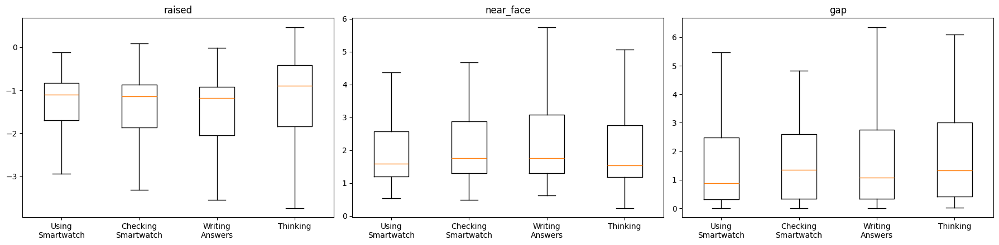

R_THR=-0.30  F_THR=0.95  G_THR=0.89  V_THR=0.017


In [86]:
SHOW = ["Using_Smartwatch", "Checking_Smartwatch", "Writing_Answers", "Thinking"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["raised", "near_face", "gap"]):
    data = [sig.loc[sig["action"] == a, col].dropna() for a in SHOW]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, len(SHOW) + 1), [a.replace("_", "\n") for a in SHOW])
    ax.set_title(col)
plt.tight_layout(); plt.show()

normal = sig[sig["action"].isin(["Writing_Answers", "Thinking"])]
R_THR = normal["raised"].quantile(0.90)      # tangan lebih tinggi dari 90% frame menulis/berpikir
F_THR = normal["near_face"].quantile(0.10)   # tangan lebih dekat wajah dari 90% frame menulis/berpikir
G_THR = sig.loc[sig["action"] == "Using_Smartwatch", "gap"].quantile(0.50)
V_THR = sig["head_vel"].quantile(0.50)       # kepala "diam"
print(f"R_THR={R_THR:.2f}  F_THR={F_THR:.2f}  G_THR={G_THR:.2f}  V_THR={V_THR:.3f}")


In [87]:
FPS = 10

def longest_run_s(mask):
    m = pd.Series(mask.astype(float)).rolling(5, center=True, min_periods=1).mean() > 0.5  # tambal celah 1-2 frame
    best = cur = 0
    for v in m:
        cur = cur + 1 if v else 0
        best = max(best, cur)
    return best / FPS

def watch_feats(kp):
    S = watch_signals(kp)
    watch_pose = (S["raised"] > R_THR) | (S["near_face"] < F_THR)   # tangan diangkat / didekatkan ke wajah
    watch_use  = watch_pose & (S["gap"] < G_THR)                    # + tangan kanan ke tangan kiri
    watch_hold = watch_pose & (S["head_vel"] < V_THR)               # + kepala ditahan diam
    return dict(
        v_watch_pose_s=longest_run_s(watch_pose.to_numpy()),
        v_watch_use_s=longest_run_s(watch_use.to_numpy()),
        v_watch_hold_s=longest_run_s(watch_hold.to_numpy()),
        v_watch_pose_frac=watch_pose.mean(),
        v_watch_use_frac=watch_use.mean(),
        v_raised_p90=S["raised"].quantile(0.90),
        v_near_face_p10=S["near_face"].quantile(0.10),
        v_gap_p10=S["gap"].quantile(0.10),
    )

# train: satu video penuh per key
vf_train = pd.DataFrame([dict(key=k, **watch_feats(train_poses[k])) for k in train_df["key"]])

# test: sambung klip-klip satu chain sesuai urutan, lalu hitung fitur yang sama
vf_test = []
for gid, d in groups.sort_values("pos").groupby("group"):
    kp = np.concatenate([test_poses[s] for s in d["seq"]])
    vf_test.append(dict(group=gid, **watch_feats(kp)))
vf_test = pd.DataFrame(vf_test)

VCOLS = [c for c in vf_train.columns if c.startswith("v_")]
clips = clips.drop(columns=VCOLS, errors="ignore").merge(vf_train, on="key", how="left")
tf = test_feat.drop(columns=VCOLS + ["seq", "group", "pos", "p", "p_group"], errors="ignore")
tf = tf.merge(groups, left_on="id", right_on="seq", how="left").merge(vf_test, on="group", how="left")
test_feat = tf
print(clips.shape, test_feat.shape)


(12775, 97) (1515, 95)


Check the hypothesis: Using_Smartwatch should hold the watch pose longer than Checking_Smartwatch and Writing_Answers.

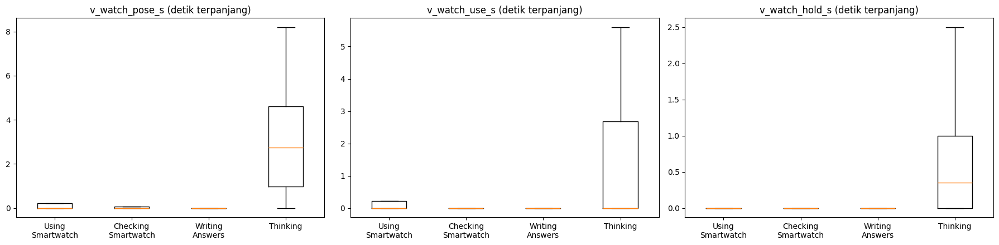

                           v_watch_pose_s  v_watch_use_s  v_watch_hold_s
action              view                                                
Checking_Smartwatch front             0.0            0.0             0.0
                    side              0.0            0.0             0.0
Thinking            front             1.8            0.0             0.0
                    side              3.7            2.8             0.8
Using_Smartwatch    front             0.0            0.0             0.0
                    side              0.4            0.4             0.0
Writing_Answers     front             0.0            0.0             0.0
                    side              0.0            0.0             0.0


In [88]:
chk = vf_train.merge(train_df[["key", "action", "view"]], on="key")
chk = chk[chk["action"].isin(SHOW)]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["v_watch_pose_s", "v_watch_use_s", "v_watch_hold_s"]):
    ax.boxplot([chk.loc[chk["action"] == a, col] for a in SHOW], showfliers=False)
    ax.set_xticks(range(1, len(SHOW) + 1), [a.replace("_", "\n") for a in SHOW])
    ax.set_title(f"{col} (detik terpanjang)")
plt.tight_layout(); plt.show()
print(chk.groupby(["action", "view"])[["v_watch_pose_s", "v_watch_use_s", "v_watch_hold_s"]].median().round(1))


In [89]:
META  = ["key", "subject", "view", "action", "label", "t0", "oof"]   # oof must never be a feature
FEATS = [c for c in clips.columns if c not in META]
X, y, g = clips[FEATS], clips.label.to_numpy(), clips.subject

params = dict(objective="binary", learning_rate=0.03, num_leaves=15, min_child_samples=40,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
              n_estimators=2000, random_state=42, deterministic=True, force_row_wise=True,
              verbose=-1)

oof, models = np.zeros(len(X)), []
for fold, (ti, vi) in enumerate(GroupKFold(5).split(X, y, g)):
    m = lgb.LGBMClassifier(**params)
    m.fit(X.iloc[ti], y[ti], eval_set=[(X.iloc[vi], y[vi])],
          callbacks=[lgb.early_stopping(100, verbose=False)])
    oof[vi] = m.predict_proba(X.iloc[vi])[:, 1]
    models.append(m)
    print(fold, round(f1_score(y[vi], oof[vi] > 0.5, average="macro"), 4))

ths = np.linspace(0.2, 0.8, 61)
clip_scores = [f1_score(y, oof > t, average="macro") for t in ths]
print("klip  OOF F1:", round(max(clip_scores), 4), "@", ths[np.argmax(clip_scores)].round(2))

0 0.5903
1 0.655
2 0.6727
3 0.6187
4 0.6635
klip  OOF F1: 0.6425 @ 0.48


In [90]:
clips["oof"] = oof
vid = clips.groupby("key").agg(label=("label", "first"), action=("action", "first"),
                               view=("view", "first"), p=("oof", "mean"))
vid_scores = [f1_score(vid.label, vid.p > t, average="macro") for t in ths]
best_t = ths[np.argmax(vid_scores)]
print("video OOF F1:", round(max(vid_scores), 4), "@", best_t.round(2))

vid["ok"] = (vid.p > best_t) == vid.label
print(vid.pivot_table(index="action", columns="view", values="ok").round(2))  

video OOF F1: 0.6668 @ 0.49
view                    front  side
action                             
Checking_Smartwatch      0.54  0.42
Looking_Around           0.46  0.31
Looking_Under_the_Desk   0.96  0.85
Reading_Hidden_Notes     0.62  0.81
Repeated_Peeking         0.65  0.85
Thinking                 1.00  0.96
Using_Smartwatch         0.92  0.58
Writing_Answers          0.62  0.19


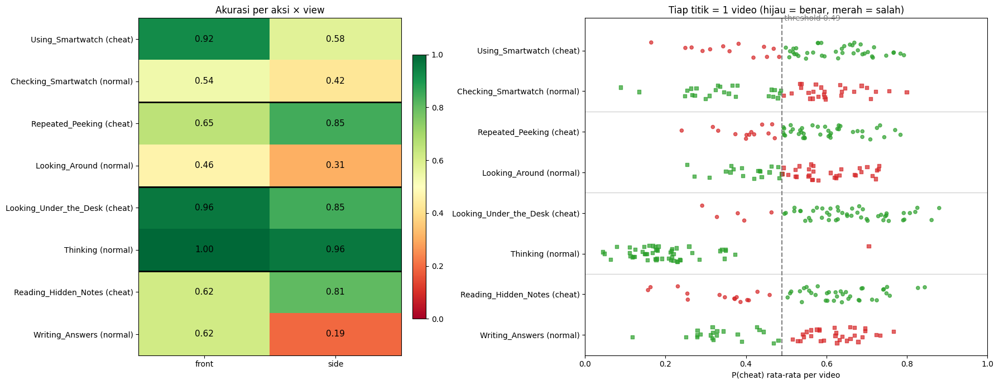

In [91]:
PAIRS = [("Using_Smartwatch", "Checking_Smartwatch"),
         ("Repeated_Peeking", "Looking_Around"),
         ("Looking_Under_the_Desk", "Thinking"),
         ("Reading_Hidden_Notes", "Writing_Answers")]
ORDER = [a for pair in PAIRS for a in pair]
CHEAT = {c for c, _ in PAIRS}
LABELS = [f"{a} ({'cheat' if a in CHEAT else 'normal'})" for a in ORDER]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1.4]})

# 1) akurasi per aksi x view
acc = vid.pivot_table(index="action", columns="view", values="ok").reindex(ORDER)
im = ax1.imshow(acc.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax1.set_xticks(range(acc.shape[1]), acc.columns)
ax1.set_yticks(range(len(ORDER)), LABELS)
for i in range(acc.shape[0]):
    for j in range(acc.shape[1]):
        ax1.text(j, i, f"{acc.values[i, j]:.2f}", ha="center", va="center", fontsize=11)
for k in range(1, len(PAIRS)):
    ax1.axhline(2 * k - 0.5, color="black", lw=2)
ax1.set_title("Akurasi per aksi × view")
fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)

# 2) P(cheat) tiap video per aksi
for i, a in enumerate(ORDER):
    d = vid[vid["action"] == a]
    jitter = np.random.default_rng(i).uniform(-0.2, 0.2, len(d))
    ax2.scatter(d["p"], i + jitter, s=20, alpha=0.7,
                c=np.where(d["ok"], "tab:green", "tab:red"),
                marker="o" if a in CHEAT else "s")
for k in range(1, len(PAIRS)):
    ax2.axhline(2 * k - 0.5, color="lightgray", lw=1)
ax2.axvline(best_t, ls="--", c="gray")
ax2.text(best_t, -0.7, f" threshold {best_t:.2f}", color="gray", va="bottom")
ax2.set_yticks(range(len(ORDER)), LABELS)
ax2.set_ylim(len(ORDER) - 0.5, -0.8)
ax2.set_xlim(0, 1)
ax2.set_xlabel("P(cheat) rata-rata per video")
ax2.set_title("Tiap titik = 1 video (hijau = benar, merah = salah)")

plt.tight_layout(); plt.show()

### Failure analysis: what did the model predict instead?
The binary model only outputs cheat / normal, so a wrong video is always "predicted the other class".
To see **which action** a failed video looks like (e.g. *Writing_Answers (normal) was predicted cheat, and it looks most like Using_Smartwatch*),
an 8-class action model is trained on the same features and the same GroupKFold folds. For each video the binary model got wrong,
`looks_like` is the most likely action **on the predicted side** (cheat actions if it was predicted cheat, normal actions if it was predicted normal).

In [92]:
# The binary model only says cheat / normal. To answer "it failed on Writing_Answers, what did it
# think it was instead?", train an 8-class ACTION model on the same features and the same
# GroupKFold folds, then read its OOF guess for every video the binary model got wrong.
ACTIONS = sorted(clips["action"].unique())
a2i = {a: i for i, a in enumerate(ACTIONS)}
ya = clips["action"].map(a2i).to_numpy()

params_mc = {**params, "objective": "multiclass", "num_class": len(ACTIONS)}
oof_mc = np.zeros((len(X), len(ACTIONS)))
for fold, (ti, vi) in enumerate(GroupKFold(5).split(X, ya, g)):   # same subjects per fold as binary
    m = lgb.LGBMClassifier(**params_mc)
    m.fit(X.iloc[ti], ya[ti], eval_set=[(X.iloc[vi], ya[vi])],
          callbacks=[lgb.early_stopping(100, verbose=False)])
    oof_mc[vi] = m.predict_proba(X.iloc[vi])

# video level: mean of clip probabilities, like the binary model
P = pd.DataFrame(oof_mc, columns=ACTIONS)
P["key"] = clips["key"].to_numpy()
Pv = P.groupby("key")[ACTIONS].mean()
vid["pred_action"] = Pv.loc[vid.index].idxmax(axis=1)
vid["pred_action_p"] = Pv.loc[vid.index].max(axis=1)
vid["pred_label"] = (vid["p"] > best_t).astype(int)
print("8-class video OOF accuracy:", round((vid["pred_action"] == vid["action"]).mean(), 3))

8-class video OOF accuracy: 0.418


In [93]:
fail = vid[~vid["ok"]].copy()
# for a failure, the binary model chose the OTHER class, so the useful answer is the closest action
# of the predicted class: e.g. Writing_Answers (normal) predicted cheat -> which cheat action?
side_cols = lambda lab: [a for a in ACTIONS if (a in CHEAT) == bool(lab)]
fail["looks_like"] = [Pv.loc[k, side_cols(r.pred_label)].idxmax() for k, r in fail.iterrows()]

summary = (fail.groupby(["action", "looks_like"]).size().rename("n").reset_index()
           .sort_values(["action", "n"], ascending=[True, False]))
tot = vid.groupby("action").size()
summary["share_of_fails"] = (summary["n"] / summary.groupby("action")["n"].transform("sum")).round(2)

print(f"\n{len(fail)} / {len(vid)} videos wrong at threshold {best_t:.2f}\n")
for a in ORDER:
    s = summary[summary["action"] == a]
    if s.empty:
        print(f"{a:<24} ({'cheat' if a in CHEAT else 'normal'}): 0 / {tot[a]} wrong"); continue
    other = "normal" if a in CHEAT else "cheat"
    by_view = fail[fail["action"] == a]["view"].value_counts().to_dict()
    print(f"{a:<24} ({'cheat' if a in CHEAT else 'normal'}): {s.n.sum()} / {tot[a]} wrong "
          f"-> predicted {other}  {by_view}")
    for _, r in s.iterrows():
        print(f"      looks like {r.looks_like:<24} {r.n:3d}  ({r.share_of_fails:.0%})")


137 / 416 videos wrong at threshold 0.49

Using_Smartwatch         (cheat): 13 / 52 wrong -> predicted normal  {'side': 11, 'front': 2}
      looks like Checking_Smartwatch        9  (69%)
      looks like Writing_Answers            2  (15%)
      looks like Looking_Around             1  (8%)
      looks like Thinking                   1  (8%)
Checking_Smartwatch      (normal): 27 / 52 wrong -> predicted cheat  {'side': 15, 'front': 12}
      looks like Using_Smartwatch          15  (56%)
      looks like Repeated_Peeking           5  (19%)
      looks like Looking_Under_the_Desk     4  (15%)
      looks like Reading_Hidden_Notes       3  (11%)
Repeated_Peeking         (cheat): 13 / 52 wrong -> predicted normal  {'front': 9, 'side': 4}
      looks like Looking_Around             6  (46%)
      looks like Checking_Smartwatch        4  (31%)
      looks like Writing_Answers            3  (23%)
Looking_Around           (normal): 32 / 52 wrong -> predicted cheat  {'side': 18, 'front': 14}

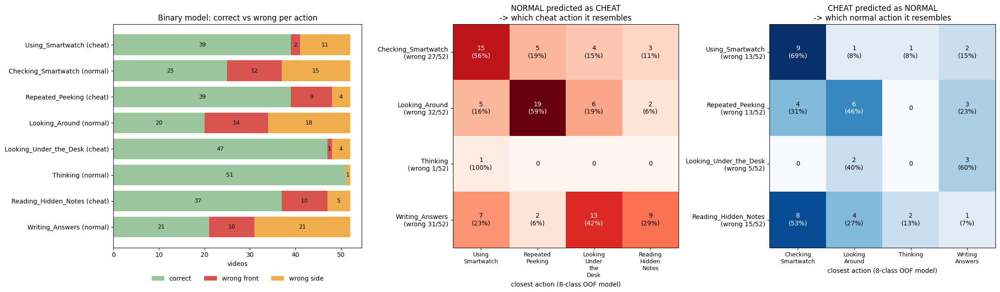

In [ ]:
NORMAL_A = [a for a in ORDER if a not in CHEAT]
CHEAT_A  = [a for a in ORDER if a in CHEAT]

fig, axes = plt.subplots(1, 3, figsize=(22, 6.5), gridspec_kw={"width_ratios": [1.1, 1, 1]})

ax = axes[0]
cnt = vid.assign(res=np.where(vid["ok"], "correct", "wrong " + vid["view"])) \
         .pivot_table(index="action", columns="res", values="p", aggfunc="size", fill_value=0) \
         .reindex(ORDER)
colors = {"correct": "#9bc59d", "wrong front": "#d9534f", "wrong side": "#f0ad4e"}
left = np.zeros(len(cnt))
for c in ["correct", "wrong front", "wrong side"]:
    v = cnt.get(c, pd.Series(0, index=cnt.index)).to_numpy()
    ax.barh(range(len(cnt)), v, left=left, color=colors[c], label=c)
    for i, (l, x) in enumerate(zip(left, v)):
        if x: ax.text(l + x / 2, i, int(x), ha="center", va="center", fontsize=9)
    left += v
ax.set_yticks(range(len(ORDER)), LABELS); ax.invert_yaxis()
ax.set_xlabel("videos"); ax.set_title("Binary model: correct vs wrong per action")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)

def heat(ax, rows, cols, title, cmap):
    M = (fail[fail["action"].isin(rows)]
         .pivot_table(index="action", columns="looks_like", values="p", aggfunc="size", fill_value=0)
         .reindex(index=rows, columns=cols, fill_value=0))
    ax.imshow(M.values, cmap=cmap, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            n = M.values[i, j]
            ax.text(j, i, f"{n}\n({n / max(M.values[i].sum(), 1):.0%})" if n else "0",
                    ha="center", va="center", fontsize=10,
                    color="white" if n > M.values.max() * 0.6 else "black")
    ax.set_xticks(range(len(cols)), [c.replace("_", "\n") for c in cols], fontsize=9)
    ax.set_yticks(range(len(rows)), [f"{r}\n(wrong {M.values[i].sum()}/{tot[r]})" for i, r in enumerate(rows)])
    ax.set_xlabel("closest action (8-class OOF model)"); ax.set_title(title)

heat(axes[1], NORMAL_A, CHEAT_A, "NORMAL predicted as CHEAT\n-> which cheat action it resembles", "Reds")
heat(axes[2], CHEAT_A, NORMAL_A, "CHEAT predicted as NORMAL\n-> which normal action it resembles", "Blues")
plt.tight_layout()
os.makedirs("metrics", exist_ok=True)
plt.savefig("metrics/error-analysis-failures.png", dpi=120, bbox_inches="tight")
plt.show()

In [96]:
test_feat["p"] = np.mean([m.predict_proba(test_feat[FEATS])[:, 1] for m in models], axis=0)
test_feat["p_group"] = test_feat.groupby("group")["p"].transform("mean")   # one video = one label

sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
sub["label"] = sub["id"].map(dict(zip(test_feat["id"], (test_feat["p_group"] > best_t).astype(int))))
assert sub["label"].notna().all()
print(sub["label"].mean())
sub.to_csv("submission.csv", index=False)


0.6422442244224422
